# Image Manipulation and Edge Detection

---

Prof. Dr.-Ing. Antje Muntzinger, Hochschule für Technik Stuttgart

antje.muntzinger@hft-stuttgart.de

---

In this notebook, we practice some basic image manipulation techniques in OpenCV including Canny edge detection. These are the foundation of later computer vision applications.

**NOTE:** You may answer in English or German.

In [ ]:
# imports
from matplotlib import pyplot as plt
%matplotlib inline

import numpy as np 
import cv2

Task 1: Basic Image Manipulation in OpenCV
=

**TODO**: 1a) Load the image 'HFT_Bau1.jpg'. Convert it to a color format of your choice, and display it. **(1.5 points)**

<function matplotlib.pyplot.show(close=None, block=None)>

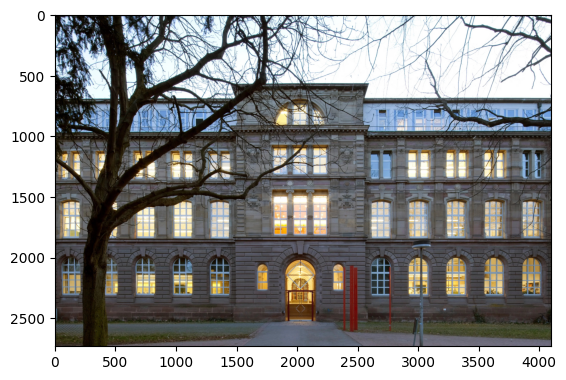

In [2]:
##### TODO: YOUR CODE GOES HERE

input_img = cv2.imread ('images/HFT_Bau1.jpg') 

img_rgb = cv2.cvtColor(input_img, cv2.COLOR_BGR2RGB)

plt.imshow(img_rgb)
plt.show

**TODO**: 1b) Color the 10th pixel row of the image in red. Plot the upper left 500x500 pixel image cutout to verify your result. **(2 points)** 

Hint: Indexing starts at 0 in Python! Remember the image origin is in the upper left image corner.

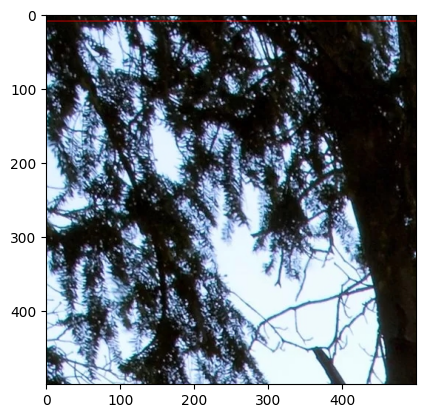

In [3]:
img_rgb[9,:] = [255, 0, 0]

img_rgbKopie= img_rgb.copy()
img_ausschnitt=img_rgbKopie[:500,:500]

plt.imshow(img_ausschnitt)
plt.show()

**TODO**: 1c) Print the color values of the rightmost Pixel in the 9th row, as well as the color values of the leftmost Pixel in the 10th row. **(2 points)** 

In [4]:
print(img_rgb[8,-1])
print(img_rgb[9,0])

[ 90 162 184]
[255   0   0]


**TODO**: 1d) Flatten the color image, i.e., convert it from the 3D array to a 1D array. Find at least two different commands that achieve the desired result. Check your output with `shape`. **(3 points)**

In [5]:
imgFlatten1 =img_rgb.flatten()
print(imgFlatten1.shape)

imgFlatten2= img_rgb.ravel()
print(imgFlatten2.shape)

(33583104,)
(33583104,)


**TODO**: 1e) As before, print the color values of the rightmost Pixel in the 9th row, as well as the color values of the leftmost Pixel in the 10th row, but use the flattened image now. Verify that the result is the same as before. **(2 points)**

In [ ]:
hoehe, breite, kanaele = img_rgb.shape

start1= (8*breite + (breite-1)) *3
print(imgFlatten1[start1:start1+3])

start2= (9*breite) *3
print(imgFlatten1[start2:start2+3])

[ 90 162 184]
[255   0   0]


**TODO**: 1f) Split the three color channels and display them separately. Can you see from the plotted images which color channel is displayed in which image (without looking at the code), or do the three channels not differ much? Write your answer in the markdown cell below the code. **(2 points)**

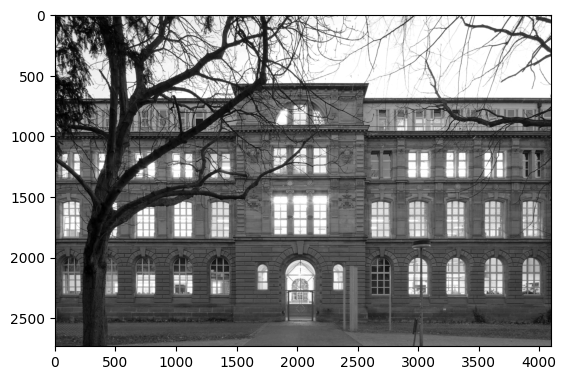

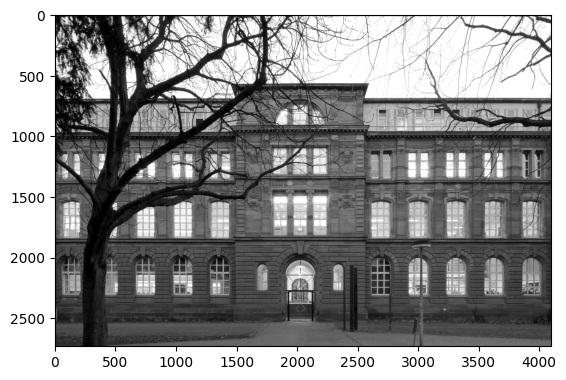

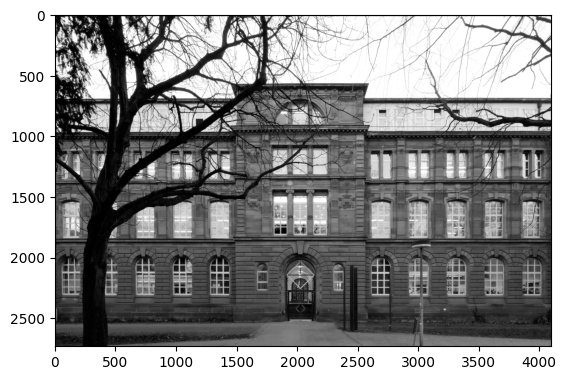

In [ ]:
#plt.imshow(img_rgb)
#plt.show()
#

r,g,b= cv2.split(img_rgb)

plt.imshow(r, cmap='gray')
plt.show()

plt.imshow(g, cmap='gray')
plt.show()

plt.imshow(b, cmap='gray')
plt.show()

**YOUR ANSWER**: 

Task 2: Edge Detection
=

**TODO**: 2a) Choose a part of the image that you find interesting for later corner and edge detection. Store the cutout in a new grayscale image. **(1 point)**

In [8]:
##### TODO: YOUR CODE GOES HERE


**TODO**: 2b) Find a part of the cutout that you think might be difficult to detect edges in with Canny. Mark this part in the grayscale cutout with a red rectangle. Write a short explanation why this could be difficult below. **(2 points)**

Hint: Note that you cannot plot color into a grayscale image. One option is to convert the grayscale image to RGB first, using `COLOR_GRAY2RGB`.

In [9]:
##### TODO: YOUR CODE GOES HERE


**YOUR ANSWER**: 

**TODO**: 2c) Resize the gray cutout to 1/4th of the original size, keeping the aspect ratio. Plot both grayscale images next to each other using Matplotlib's `subplots`. **(2 points)**

In [10]:
##### TODO: YOUR CODE GOES HERE


**TODO**: 2d) Apply Gaussian blur with a kernel of size 9 to the resized image and plot the result. **(1 point)**

In [11]:
##### TODO: YOUR CODE GOES HERE


**TODO**: 2e) Detect the edges in the blurred cutout using Canny edge detector. Adapt the Canny thresholds for an optimal result. Plot the edges in blue into the grayscale cutout. **(3 points)** 

In [12]:
##### TODO: YOUR CODE GOES HERE


**TODO**: 2f) Check if your prediction of difficulty was correct. Do you see a) real edges that were missed by Canny (false negatives) or b) detected edges that are not there in reality (false positives)? Try to experiment with the Canny thresholds and solve these difficulties. How did you try to solve the difficulties? Write your answer below the code. **(1.5 points)**

**YOUR ANSWER**: 

Well done, you are now able to apply basic image manipulation techniques as well as Canny edge detection to images in OpenCV! 

Task 3: Theory Questions
=

**TODO**: 3a) What is the problem of applying image derivatives for edge detection in noisy images? What is a possible solution to that problem? Can you give an example in which you often get noise when taking a photo? **(3 points)**

**YOUR ANSWER**: Erstmal zum Problem. Die Ableitung misst die Helligkeitsänderung zwischen benachbarten Pixeln und das Rauschen sind viele kleine, zufällige Helligkeitsänderungen, wobei sich diese Werte dann stark voneinander unterscheiden. Die Ableitung kann dabei nicht unterscheiden, ob der Sprung von einer echten Kante kommt oder vom Rauschen. Die Folge daraus ist, dass viele falsche Kanten entstehen, wobei die echten Kanten untergehen, weil das Rauschen zu stark ist.

Zur Lösung: Man könnte vor dem Ableiten das Bild mithilfe eines Gauß-Filters glätten. Der Gauß-Filter ersetzt dabei jeden Pixel durch einen gewichteten Durchschnitt seiner Nachbarn. Das zufällige Rauschen gleicht sich also aus und die echten Kanten bzw. die großen Sprünge bleiben. Man muss jedoch auch aufpassen, dass man nicht zu viel glättet, weil sich sonst natürlich auch die echten Kanten verwischen und man könnte die Filter auch kombinieren. Man könnte Glätten und Ableiten in einem machen, wobei man dann vom Derivative of Gaussian spricht.

Typische Beispiele sind Fotos, die bei wenig Licht entstanden sind vor allem in der Dämmerung, dunklen Räumen oder auch nachts und wenn dann der Sensor zusätzlich noch kleiner ist und nicht so lichtempfindlich ist, braucht man oft große ISO-Werte, wobei man das Bild also künstlich aufhellt und dabei entsteht oft das typische Rauschen und das Bild wirkt schnell körnig.

**TODO**: 3b) You are given a 3×3 pixel input image $
\begin{array}{|ccc|}
\hline
 1 & 2 & 1  \\ 
 2 & 2 & 2  \\ 
 3 & 2 & 3  \\ 
\hline   
\end{array}$
and a 3×3 pixel filter $\begin{array}{|ccc|}
\hline
 -1 & 0 & 1  \\ 
 -1 & 0 & 1  \\ 
 -1 & 0 & 1  \\ 
\hline   
\end{array}$. Compute the 3 × 3 pixel result image of the correlation of the filter with the input image. All pixels outside the input image are padded with zeros. **(4.5 points)**

**YOUR ANSWER**: 
```
(1,1) = (-1)*0 + 0*0 + 1*0 + (-1)*0 + 0*1 + 1*2 + (-1)*0 + 0*2 + 1*2 = 4
(1,2) = (-1)*0 + 0*0 + 1*0 + (-1)*1 + 0*2 + 1*1 + (-1)*2 + 0*2 + 1*2 = 0
(1,3) = (-1)*0 + 0*0 + 1*0 + (-1)*2 + 0*1 + 1*0 + (-1)*2 + 0*2 + 1*0 = -4
(2,1) = (-1)*0 + 0*1 + 1*2 + (-1)*0 + 0*2 + 1*2 + (-1)*0 + 0*3 + 1*2 = 6
(2,2) = (-1)*1 + 0*2 + 1*1 + (-1)*2 + 0*2 + 1*2 + (-1)*3 + 0*2 + 1*3 = 0
(2,3) = (-1)*2 + 0*1 + 1*0 + (-1)*2 + 0*2 + 1*0 + (-1)*2 + 0*3 + 1*0 = -6
(3,1) = (-1)*0 + 0*2 + 1*2 + (-1)*0 + 0*3 + 1*2 + (-1)*0 + 0*0 + 1*0 = 4
(3,2) = (-1)*2 + 0*2 + 1*2 + (-1)*3 + 0*2 + 1*3 + (-1)*0 + 0*0 + 1*0 = 0
(3,3) = (-1)*2 + 0*2 + 1*0 + (-1)*2 + 0*3 + 1*0 + (-1)*0 + 0*0 + 1*0 = -4
```

Pixel result image:

    4  0  -4
    6  0  -6
    4  0  -4


**TODO**: 3c) What patterns does this special filter respond to? How can you see this in the result from 3b)? **(2 points)**

**YOUR ANSWER**: 

**TODO**: 3d) Please calculate the result using the settings from task 3b), but with convolution instead of correlation. **(4.5 points)**

**YOUR ANSWER**: 
